# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import CNAMCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Multilabel mask

In [ ]:
dataset_config = {
    "data_dir" : "./data/cnam_cd/",
    "task_type": "multilabel"
}
dataset = CNAMCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 2508


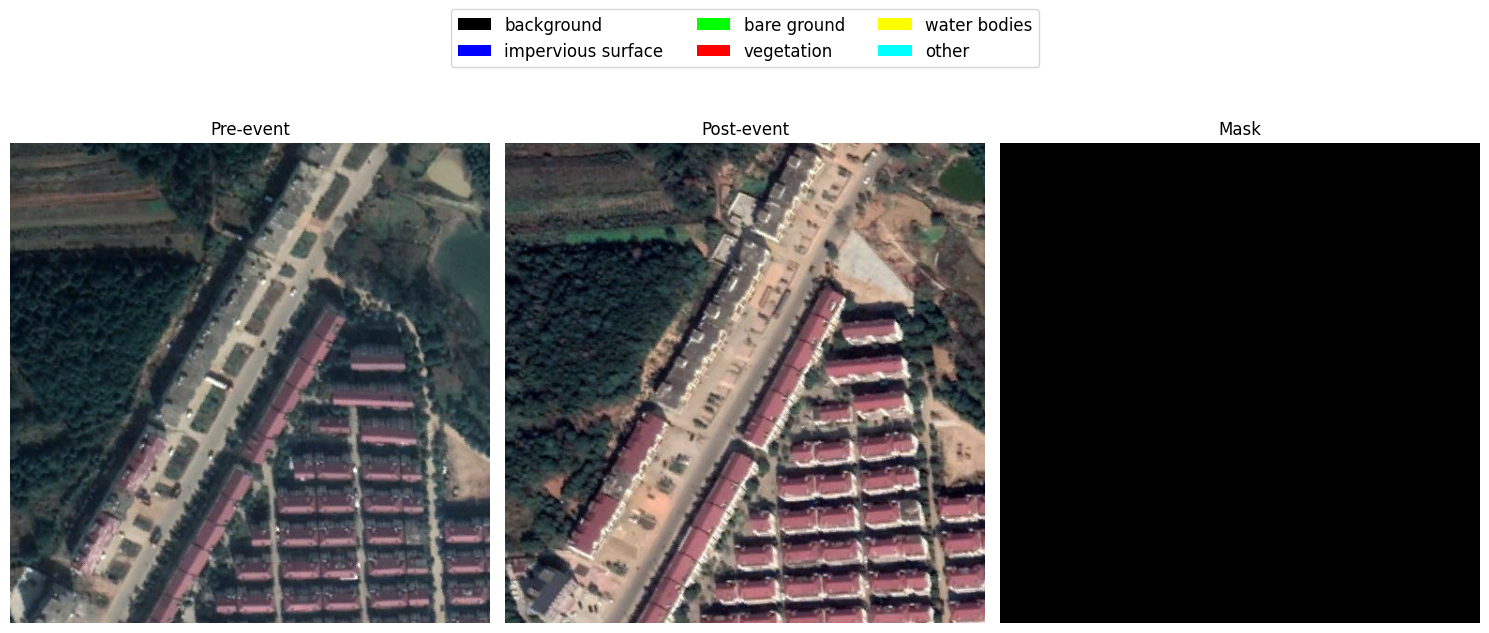

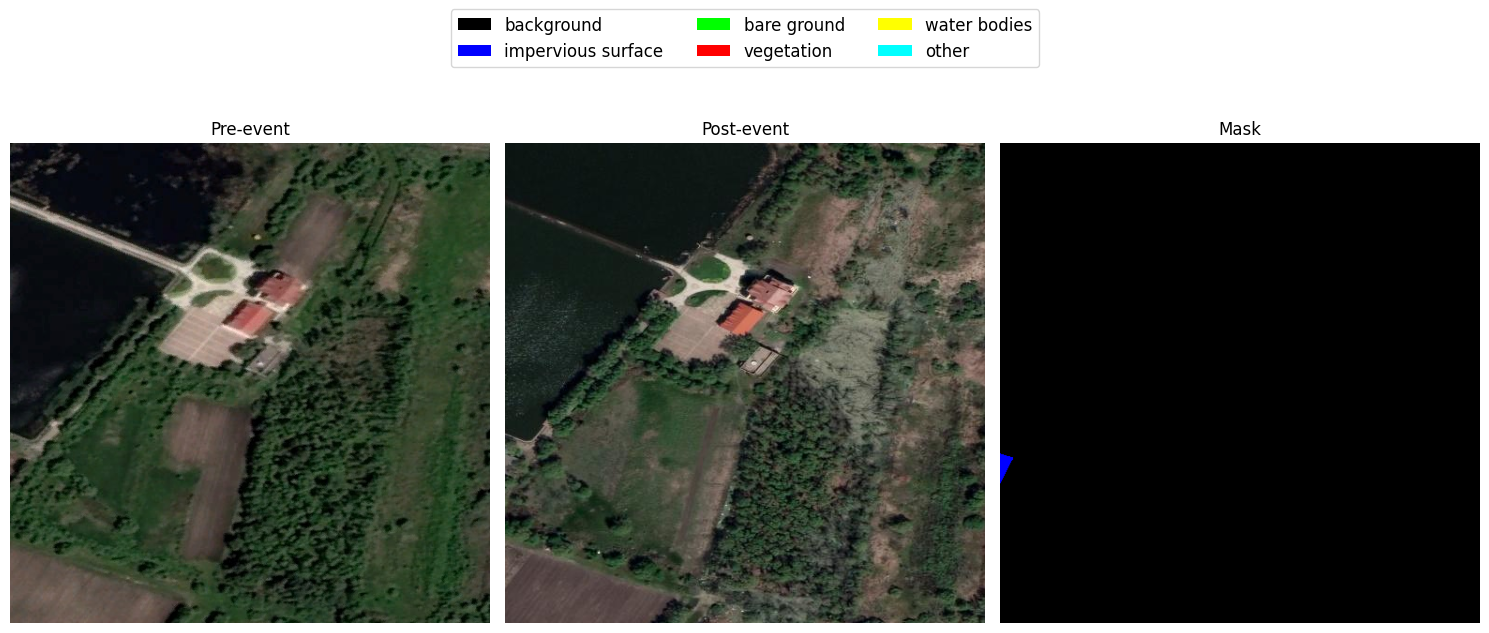

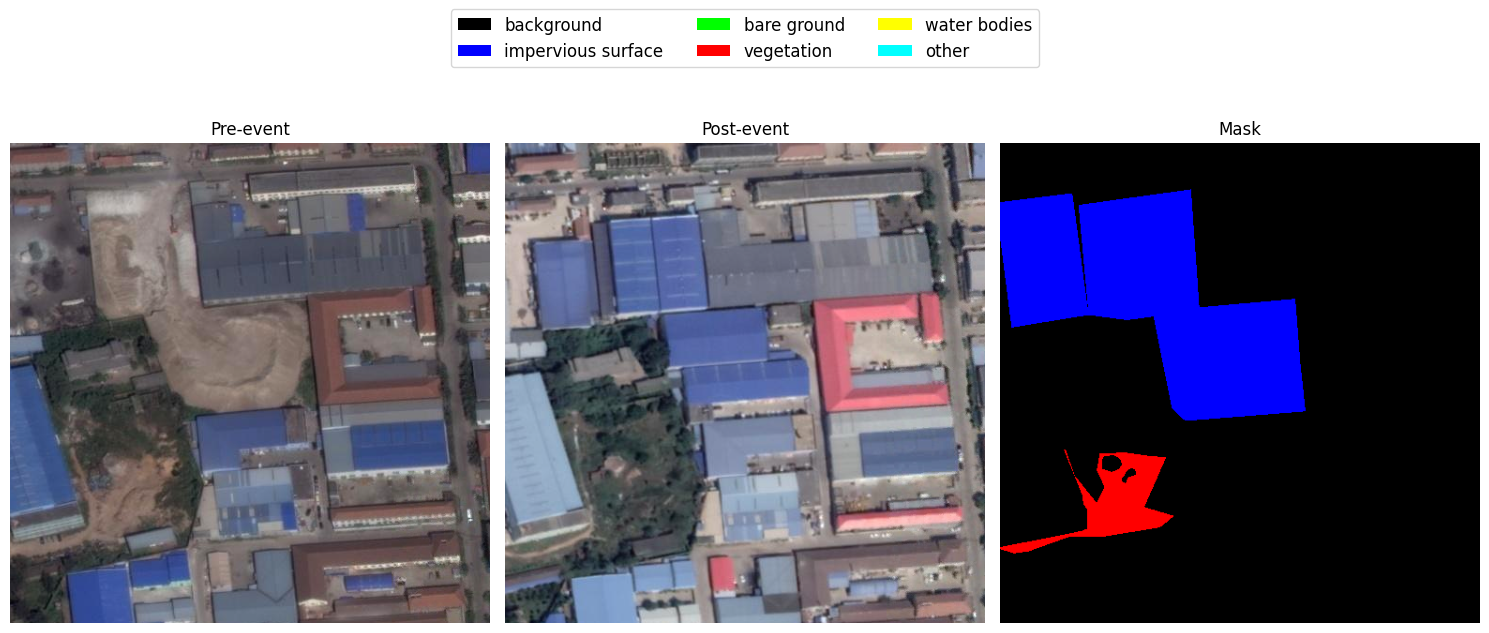

In [16]:
dataset.show_image(1000);
dataset.show_image(15);
dataset.show_image(22);

In [23]:
dataset.data_distribution_table()

,Number of pixels
background,474561097.0
impervious surface,48595337.0
bare ground,64577658.0
vegetation,28836601.0
water bodies,25948065.0
other,14938394.0


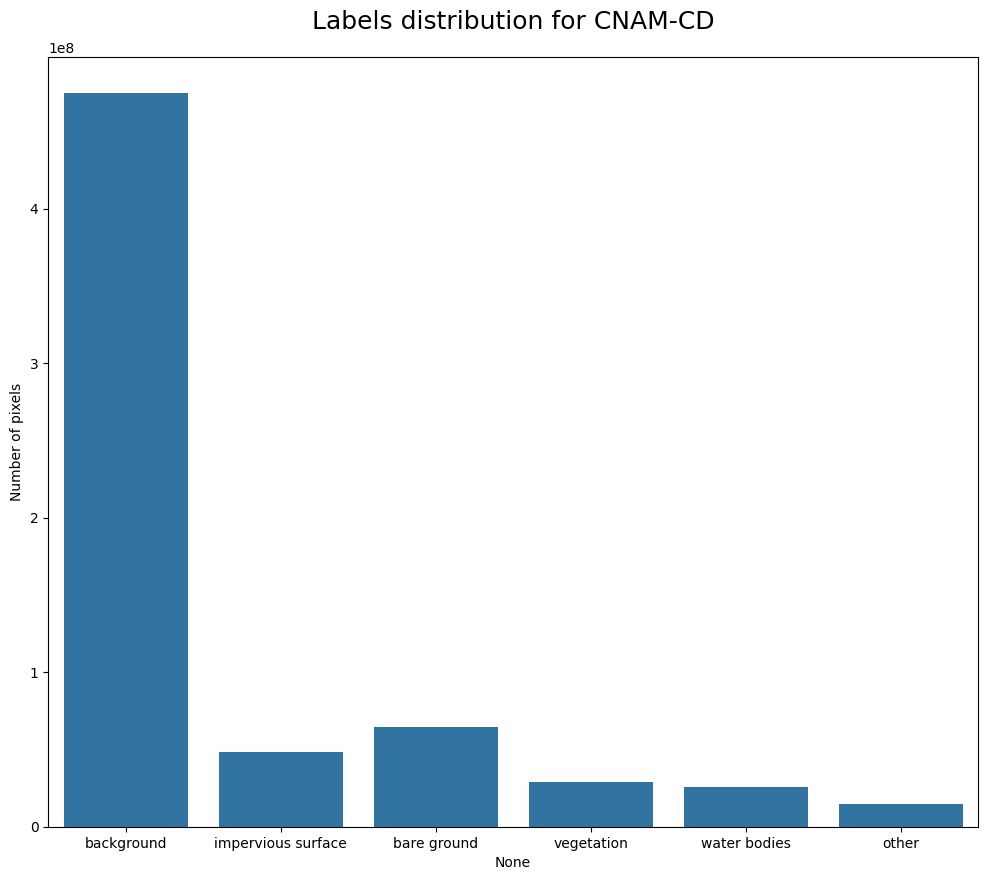

In [24]:
dataset.data_distribution_barchart();

Binary mask

Total number of patches: 2508


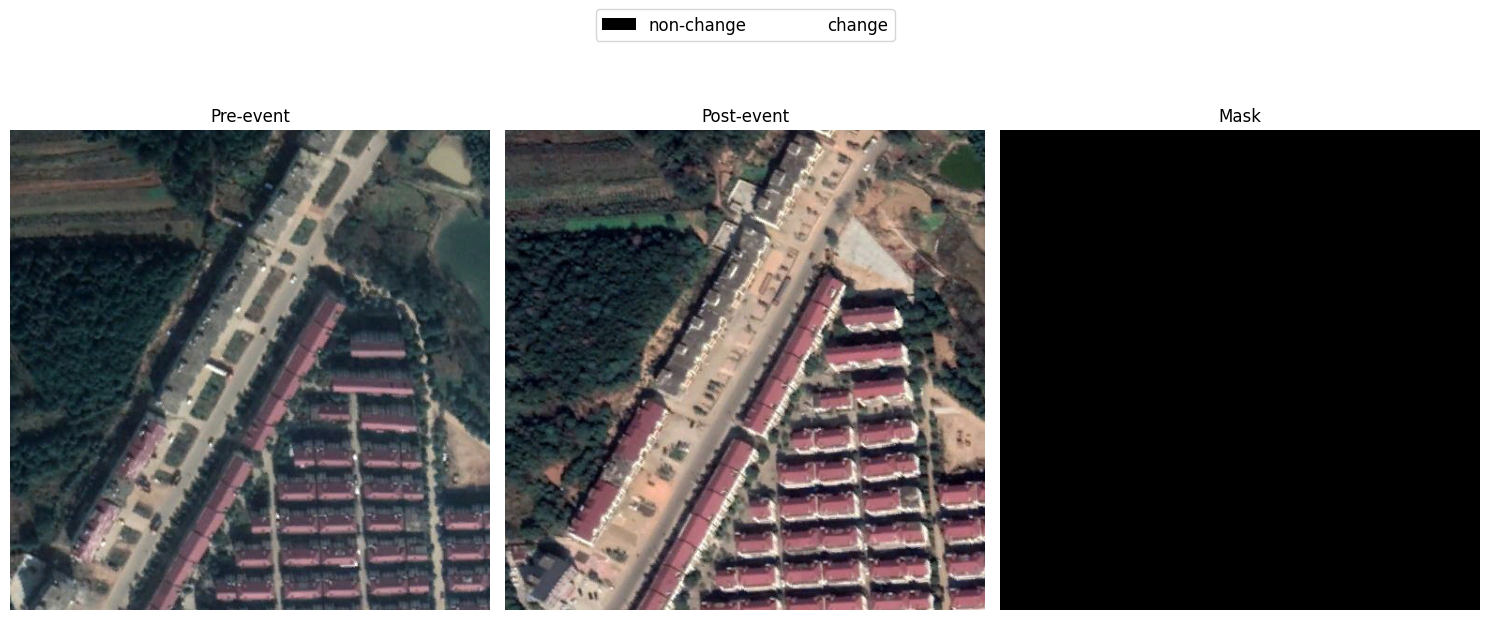

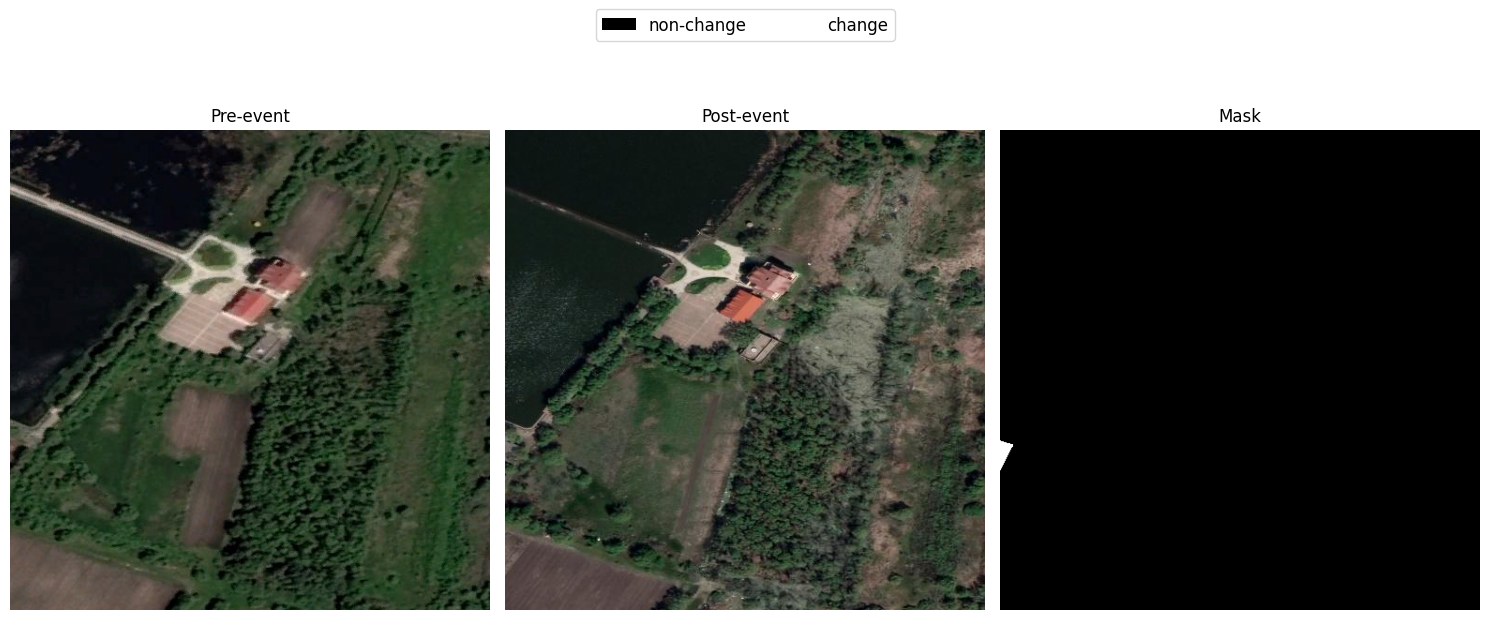

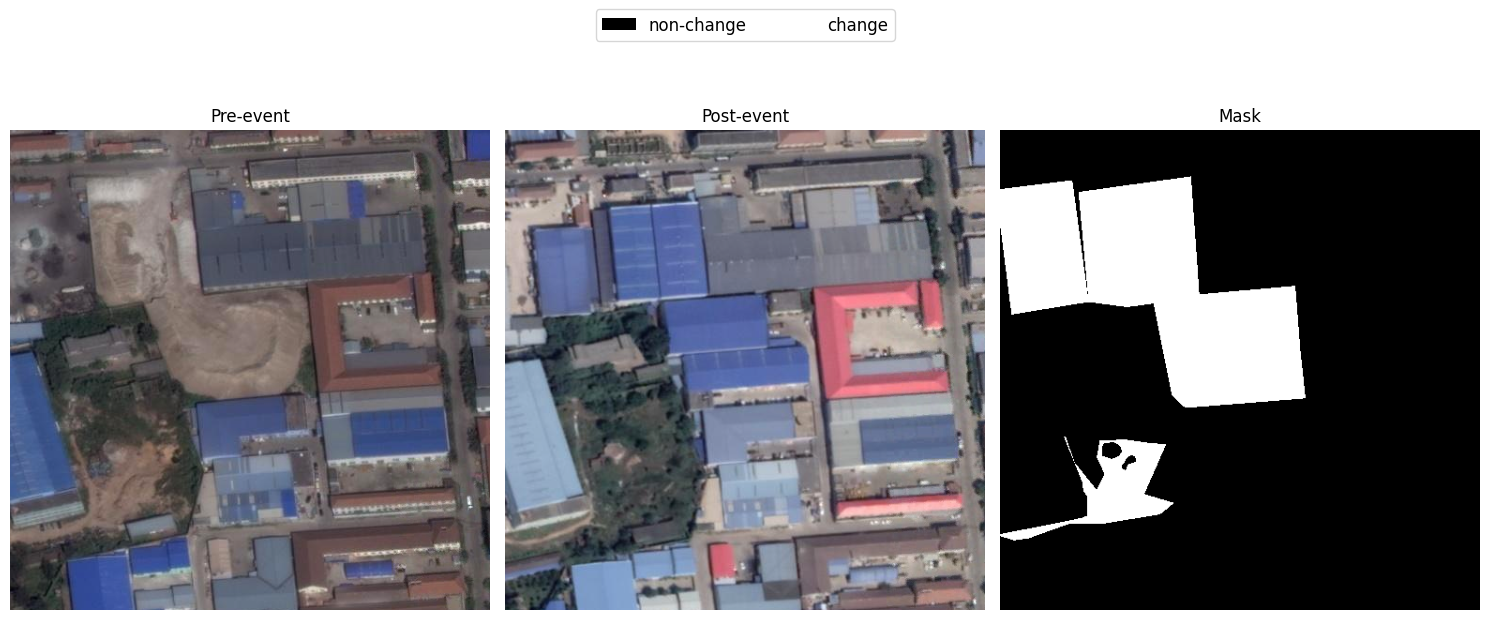

In [ ]:
dataset_config = {
    "data_dir" : "./data/cnam_cd/",
    "task_type": "binary"
}
dataset = CNAMCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1000);
dataset.show_image(15);
dataset.show_image(22);

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/cnam_cd/",
    "task_type": "binary",
    "csv_file": "./data/cnam_cd/cnam_cd_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = CNAMCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/cnam_cd/",
    "task_type": "binary",
    "csv_file": "./data/cnam_cd/cnam_cd_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = CNAMCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1506, 501)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/cnam_cd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 09:46:24,448 INFO Starting training.
training: 100%|██████████| 95/95 [03:21<00:00,  2.12s/it]
2026-01-28 09:49:45,928 INFO epoch: 1, loss:  0.26585
testing on train set: 100%|██████████| 95/95 [03:20<00:00,  2.11s/it]
2026-01-28 09:53:07,501 INFO Accuracy:0.7243812327999201, Accuracy per Class:[0.70944284 0.73931963], Precision Micro:0.7096843609701504, Precision Macro:0.6486071638132906, Precision Weighted:0.676961855448013, Precision per Class:[0.71011638 0.58709795], Recall Micro:0.7300868499649082, Recall Macro:0.5022063180960091, Recall Weighted:0.7300868499649081, Recall per Class:[0.99654258 0.00787005], F1_score Micro:0.7197410472370198, F1_score Macro:0.42241306208641577, F1_score Weighted:0.609978292698821, F1_score per Class:[0.82929422 0.0155319 ], IOU:0.5621839594901621, IOU mean:0.3580989527606731, IOU per Class:[0.70837117 0.00782673]
training: 100%|██████████| 95/95 [03:20<00:00,  2.11s/it]
2026-01-28 09:56:28,002 INFO epoch: 2, loss:  0.25164
testing on tra

## Predictions

2026-01-28 15:17:12,559 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cnam_cd/checkpoint.pth.tar
2026-01-28 15:17:12,896 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cnam_cd/checkpoint.pth.tar at epoch 51


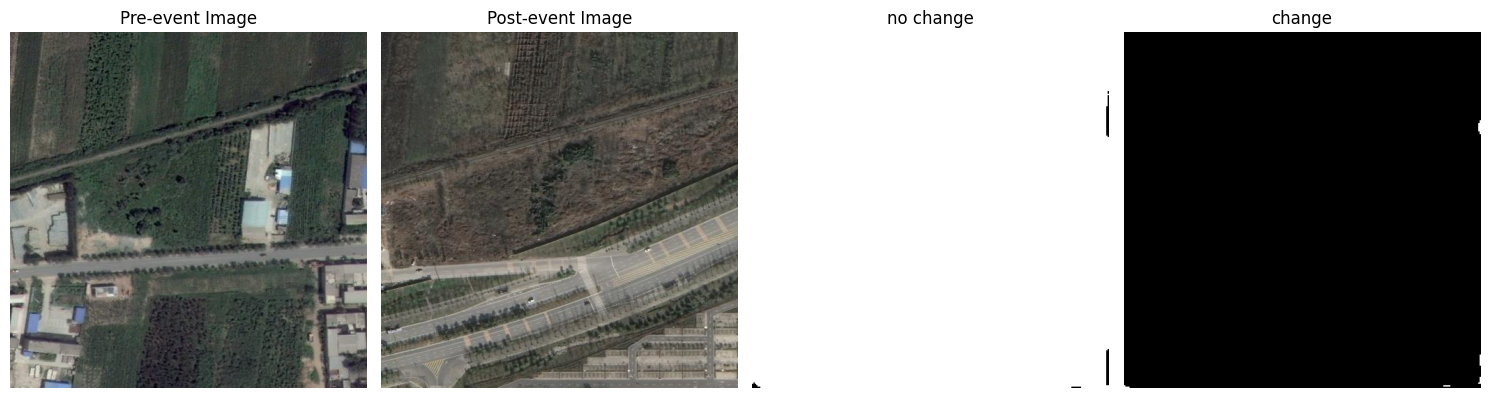

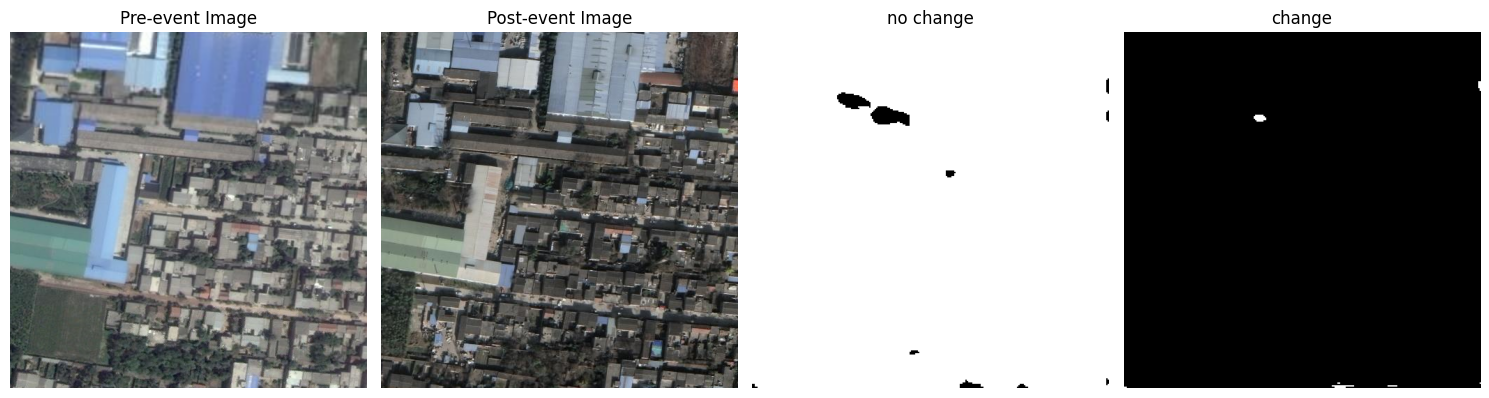

In [ ]:
model_path = "./data/experiments/cnam_cd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/cnam_cd/A/1762.tif")
image2 = image_loader("./data/cnam_cd/B/1762.tif")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/cnam_cd/A/1688.tif")
image2 = image_loader("./data/cnam_cd/B/1688.tif")
fig = model.predict_masks(image1, image2, labels, transform)